## Decision Trees

Our goal is to use the wine classification data set in order to make wine recommendations. This time, we'll explore the use of decision trees for classification.  

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_wine
from sklearn import metrics
from sklearn.tree import DecisionTreeClassifier, plot_tree

# for forest
from sklearn.ensemble import RandomForestClassifier

# for practice
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree # note plot_tree here is identical to function plot_tree above (so it is really not needed)
from sklearn.metrics import mean_squared_error, r2_score

In [65]:
# bring in the dataset
# see https://scikit-learn.org/1.5/modules/generated/sklearn.datasets.load_wine.html
wine_data = load_wine(as_frame=True)
df = wine_data.frame
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


Do we have balance among classes of the dataset?

In [67]:
# check the percentage representation of the classes
df["target"].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

Let's visualize this data. I'll just use the first two features now and the target as the class/hue.

<Axes: xlabel='alcohol', ylabel='malic_acid'>

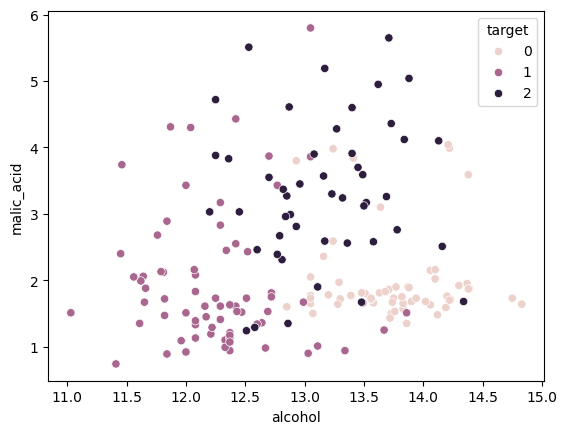

In [70]:
sns.scatterplot(x=df['alcohol'],y=df['malic_acid'], hue=df['target'])

Are we missing data?

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

No data appears to be missing.

Let's split the data set. We'll use a 75/25 split.

In [76]:
# define independent variables as big/uppercase X
X = df.iloc[:, 0:13] # independent variables

# define dependent variable as y
y = df['target'] # dependent variable

# we'll split it 75/25, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.25)

Now let's set up the model using the training data.

In [105]:
# create model using DecisionTreeClassifier
classifier = DecisionTreeClassifier(max_depth=3)

# fit the model
classifier.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3)

Now that we have the model, let's do a prediction. Run this against our test data to see how it does. 

In [108]:
y_pred = classifier.predict(X_test)

In [110]:
# Print confusion matrix 
matrix = metrics.confusion_matrix(y_pred, y_test)
print(matrix)

[[17  1  0]
 [ 2 12  0]
 [ 0  1 12]]


In [112]:
# Calculate accuracy score
score = metrics.accuracy_score(y_pred, y_test)
# Print accuracy score
print('Accuracy score is ', end="")
print('%.3f' % score)

Accuracy score is 0.911


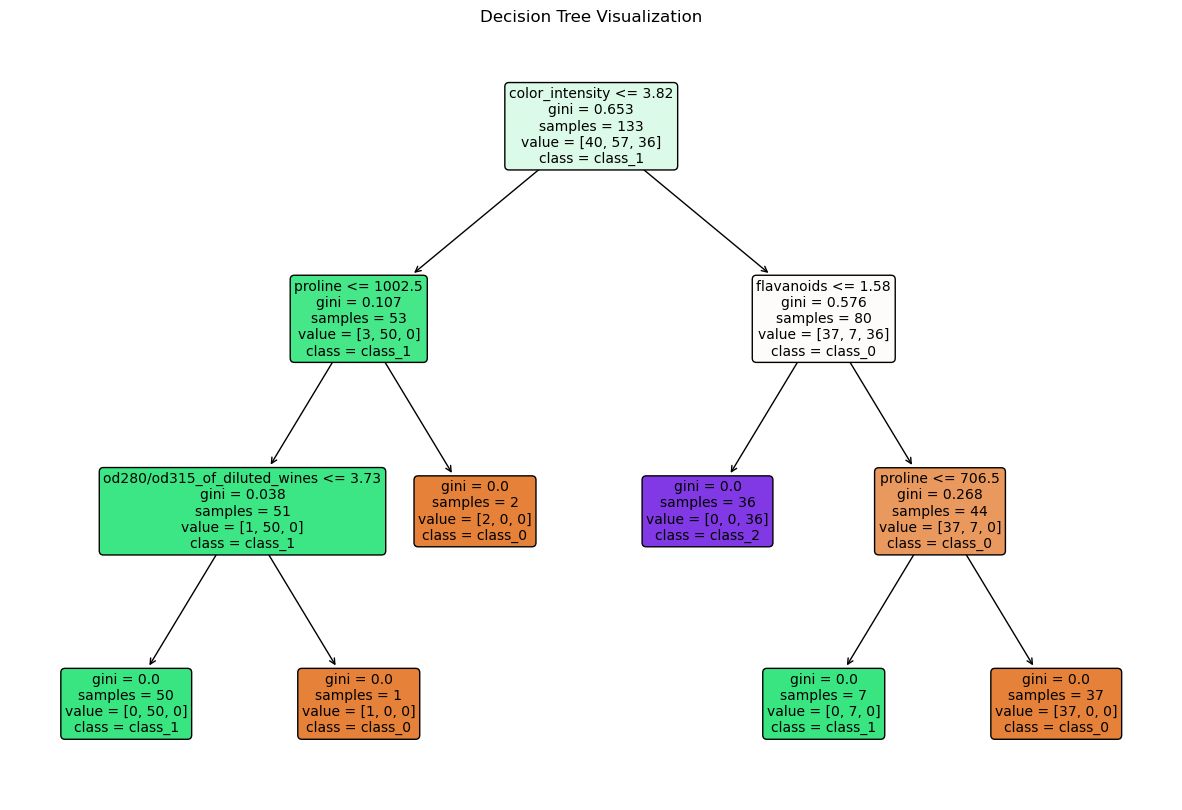

In [114]:
# now let's view the tree
plt.figure(figsize=(15, 10)) # Adjust figure size as needed
plot_tree(classifier,
          feature_names=wine_data.feature_names,
          class_names=wine_data.target_names,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Decision Tree Visualization")
plt.show()

What are we seeing in each node above?
* **gini** is the impurity of the node (0 = pure)
* **samples**  is the observations associated with the node
* **value** is the split between classes
* **class** indicates the class that has the highest frequency

Let's look at the feature importance. This shows how much each feature reduces node impurity across all splits of the tree.

In [117]:
# Access feature importances - for pruning
importances = classifier.feature_importances_
importances

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.39520117, 0.        , 0.        , 0.40394965,
       0.        , 0.02259046, 0.17825871])

In [119]:
# Create a dataframe to visualize feature importances
feature_importance_df = pd.DataFrame({'feature': wine_data.feature_names, 'importance': importances})

# Sort in order to see more clearly
feature_importance_df = feature_importance_df.sort_values('importance', ascending=False)

feature_importance_df

,feature,importance
9,color_intensity,0.403950
6,flavanoids,0.395201
12,proline,0.178259
11,od280/od315_of_diluted_wines,0.022590
0,alcohol,0.000000
1,malic_acid,0.000000
2,ash,0.000000
3,alcalinity_of_ash,0.000000
4,magnesium,0.000000
5,total_phenols,0.000000


## How about random forests?

In [ ]:
# intialize the model


In [ ]:
# fit the model


In [ ]:
# predict
y_pred = randomForest.predict(X_test)

In [ ]:
# Print confusion matrix 
matrix = metrics.confusion_matrix(y_pred, y_test)
print(matrix)

In [ ]:
# Calculate accuracy score
score = metrics.accuracy_score(y_pred, y_test)

# Print accuracy score
print('Accuracy score is ', end="")
print('%.3f' % score)

## Now you try

Use prestige.csv from a few weeks back in order to predict prestige value.

In [ ]:
# load data
df = pd.read_csv("prestige.csv")
df

In [ ]:
# drop job feature


In [ ]:
# encode type -- remember that we have to encode these categorical values when using regression
df = pd.get_dummies(df, drop_first=True)
df

In [ ]:
# split data

# define independent variables as big/uppercase X
X = df[["education", "income", "women", "census", "type_prof", "type_wc"]] # independent variables

# define dependent variable as y
y = df['prestige'] # dependent variable

# we'll split it 75/25, using 25% for training
# random_state - sets will be random each time. To have reproducible sets, use a digit here as your seed.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.25)


In [ ]:
# init model - note we are using regression instead!
tree = ???

In [ ]:
# fit the model


In [ ]:
# print out a text version of the tree -- use your "tree" name below
print(export_text(tree, feature_names=X_train.columns.to_list()))

In [ ]:
# more visual example
plt.figure(figsize=(12, 8)) # Adjust figure size as needed
plot_tree(tree_name_here,
              feature_names=X_train.columns.to_list(), # Replace with your actual feature names
              filled=True,
              rounded=True,
              fontsize=10)
plt.title("Regression Tree Visualization")
plt.show()

In [ ]:
# predict the prestige value using the test data


In [ ]:
# evaluate the model using the appropriate metric
print("RMSE: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

In [ ]:
# r squared = measures how well the this predicts the outcome
print("R2 Score: ", r2_score(y_test, y_pred))

Can you do better with the random forest regressor?